# Lecture 5 notebook: What trend following captures

Companion to Lecture 5 of *Systematic Trading Notes*. Sections are numbered as in the lecture. The question is
about the **market**, not the system: where do the profits of a trend rule come from? One rule serves as the
measuring instrument throughout, the sign of the past 12-month return, rebalanced monthly.

Data: daily adjusted closes for 16 liquid ETFs covering US, international and emerging equities, US sectors,
bonds, gold, silver, gold miners, oil and real estate, from each fund's start to the latest bar. Results on one
rule and one sample are preliminary: they describe this history, not a law.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "05-what-trend-following-captures" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]

## 1. Data

Month-end log closes; the last, incomplete month is dropped. A fund enters once it has 12 months of history,
since the rule needs a 12-month return.

In [2]:
C = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")["close"][TICKERS]
last_full = C.index[-1] - pd.offsets.MonthEnd(1)
R = np.log(C).resample("ME").last().diff().loc[:last_full]
for t in TICKERS:
    s = R[t].dropna()
    print(f"{t}: {s.index[0]:%Y-%m} to {s.index[-1]:%Y-%m}, {len(s)} months")


def trend_frame(t, lookback=12):
    r = R[t].dropna()
    s = np.sign(r.rolling(lookback).sum()).shift(1)       # position for month t, known at the end of month t-1
    return pd.concat([s, r], axis=1, keys=["s", "r"]).dropna()

SPY: 1993-02 to 2026-09, 404 months
QQQ: 1999-04 to 2026-09, 330 months
IWM: 2000-06 to 2026-09, 316 months
EFA: 2001-09 to 2026-09, 301 months
EEM: 2003-05 to 2026-09, 281 months
XLE: 1999-01 to 2026-09, 333 months
XLF: 1999-01 to 2026-09, 333 months
XLK: 1999-01 to 2026-09, 333 months
XLU: 1999-01 to 2026-09, 333 months
VNQ: 2004-10 to 2026-09, 264 months
AGG: 2003-10 to 2026-09, 276 months
TLT: 2002-08 to 2026-09, 290 months
GLD: 2004-12 to 2026-09, 262 months
SLV: 2006-05 to 2026-09, 245 months
GDX: 2006-06 to 2026-09, 244 months
USO: 2006-05 to 2026-09, 245 months


## 2. Two sources of trend profits

### 2.1 The decomposition, by hand

With position $s_t \in \{-1, +1\}$ and return $r_t$, the average trend return splits exactly into two parts
(population moments, dividing by $T$):

$$\overline{s\,r} \;=\; \underbrace{\overline{(s-\bar s)(r-\bar r)}}_{\text{timing}} \;+\; \underbrace{\bar s\,\bar r}_{\text{drift}}$$

A toy series of six months:

In [3]:
toy = pd.DataFrame({"s": [1, 1, 1, -1, -1, 1], "r": [2.0, 1.0, -3.0, -2.0, 1.0, 3.0]}, index=range(1, 7))
toy["s*r"] = toy.s * toy.r
total = toy["s*r"].mean()
drift = toy.s.mean() * toy.r.mean()
timing = ((toy.s - toy.s.mean()) * (toy.r - toy.r.mean())).mean()
display(toy.T)
print(f"average trend return {total:.4f} = timing {timing:.4f} + drift {drift:.4f}  (mean position {toy.s.mean():.4f}, mean return {toy.r.mean():.4f})")
assert np.isclose(total, timing + drift)

,1,2,3,4,5,6
s,1.0,1.0,1.0,-1.0,-1.0,1.0
r,2.0,1.0,-3.0,-2.0,1.0,3.0
s*r,2.0,1.0,-3.0,2.0,-1.0,3.0


average trend return 0.6667 = timing 0.5556 + drift 0.1111  (mean position 0.3333, mean return 0.3333)


### 2.2 The decomposition on 16 ETFs (Table 2.1)

Percent a year (monthly figures times 12). *Long side* and *short side* split the same total by the months
spent long and short.

In [4]:
rows = {}
for t in TICKERS:
    d = trend_frame(t)
    s, x = d.s, d.r
    total = (s * x).mean(); drift = s.mean() * x.mean(); timing = total - drift
    rows[t] = {"months": len(x), "asset drift": 1200 * x.mean(), "share of months long": (s > 0).mean(),
               "trend return": 1200 * total, "drift part": 1200 * drift, "timing part": 1200 * timing,
               "long side": 1200 * x[s > 0].sum() / len(x), "short side": 1200 * (-x[s < 0]).sum() / len(x)}
dec = pd.DataFrame(rows).T
dec.loc["median"] = dec.median()
display(dec.round(2))

,months,asset drift,share of months long,trend return,drift part,timing part,long side,short side
SPY,392.0,10.22,0.82,10.63,6.57,4.06,10.43,0.21
QQQ,318.0,7.86,0.80,11.13,4.70,6.43,9.49,1.64
IWM,304.0,8.11,0.69,3.84,3.15,0.69,5.98,-2.14
EFA,289.0,7.26,0.67,2.30,2.49,-0.19,4.78,-2.48
EEM,269.0,7.91,0.68,7.70,2.79,4.90,7.80,-0.11
XLE,321.0,8.29,0.68,7.89,2.97,4.92,8.09,-0.20
XLF,321.0,5.76,0.66,1.90,1.81,0.08,3.83,-1.93
XLK,321.0,8.53,0.78,10.09,4.70,5.38,9.31,0.78
XLU,321.0,7.31,0.79,6.45,4.17,2.28,6.88,-0.43
VNQ,252.0,6.12,0.73,2.38,2.77,-0.39,4.25,-1.87


### 2.3 The long and the short side live in different markets (Table 2.2)

Next month's return after a positive and after a negative 12-month return: mean and volatility, annualised.

In [5]:
rows = {}
for t in TICKERS:
    d = trend_frame(t)
    up, dn = d.r[d.s > 0], d.r[d.s < 0]
    rows[t] = {"mean after up-trend": 1200 * up.mean(), "mean after down-trend": 1200 * dn.mean(),
               "vol after up-trend": 100 * np.sqrt(12) * up.std(), "vol after down-trend": 100 * np.sqrt(12) * dn.std()}
side = pd.DataFrame(rows).T
side.loc["median"] = side.median()
display(side.round(1))

,mean after up-trend,mean after down-trend,vol after up-trend,vol after down-trend
SPY,12.7,-1.2,12.9,22.0
QQQ,11.9,-8.1,18.7,35.5
IWM,8.6,7.0,16.2,27.0
EFA,7.1,7.5,13.5,22.1
EEM,11.5,0.3,17.5,26.6
XLE,11.9,0.6,22.5,30.1
XLF,5.8,5.6,15.1,29.8
XLK,12.0,-3.5,19.0,33.7
XLU,8.8,2.0,13.8,20.0
VNQ,5.9,6.8,16.9,32.6


### 2.4 Timing is earned in episodes (Table 2.3)

Each month's contribution to the timing part, $(s_t-\bar s)(r_t-\bar r)$, split by the size of the month's move.
Linear autocorrelation, which weights all months equally, is shown for comparison: the sum of the first twelve
monthly autocorrelations.

In [6]:
rows, dec_rows = {}, []
for t in TICKERS:
    d = trend_frame(t)
    contrib = (d.s - d.s.mean()) * (d.r - d.r.mean())
    big = d.r.abs() >= d.r.abs().quantile(0.9)
    rows[t] = {"timing part": 1200 * contrib.mean(),
               "from the 10% largest moves": 1200 * contrib[big].sum() / len(d),
               "from the other 90%": 1200 * contrib[~big].sum() / len(d),
               "sum of autocorrelations, lags 1-12": sum(d.r.autocorr(k) for k in range(1, 13))}
    decile = pd.qcut(d.r.abs().rank(method="first"), 10, labels=False)
    dec_rows.append(1200 * contrib.groupby(decile).sum() / len(d))
epi = pd.DataFrame(rows).T
epi.loc["median"] = epi.median()
display(epi.round(2))
by_decile = pd.concat(dec_rows, axis=1).median(axis=1)
print("median timing contribution (% a year) by decile of |monthly move|, 1 = smallest:")
print(by_decile.round(2).to_dict())

,timing part,from the 10% largest moves,from the other 90%,"sum of autocorrelations, lags 1-12"
SPY,4.06,2.29,1.77,0.23
QQQ,6.43,6.88,-0.44,0.59
IWM,0.69,0.50,0.19,-0.15
EFA,-0.19,-0.75,0.57,-0.12
EEM,4.90,-0.27,5.17,0.02
XLE,4.92,4.14,0.78,-0.04
XLF,0.08,1.80,-1.71,0.20
XLK,5.38,5.76,-0.38,0.45
XLU,2.28,2.24,0.04,-0.02
VNQ,-0.39,0.48,-0.87,-0.04


median timing contribution (% a year) by decile of |monthly move|, 1 = smallest:
{0: -0.05, 1: -0.02, 2: 0.04, 3: 0.01, 4: 0.44, 5: -0.0, 6: 0.02, 7: 0.03, 8: -0.69, 9: 2.09}


**After a shock: the first days overshoot (Table 2.4).** Weekly returns standardised by the trailing 52-week
volatility: how often the next week has the same sign, after a week beyond 2 standard deviations and after a
normal week, and the median next-week return after a large down week.

In [7]:
W = np.log(C).resample("W-FRI").last().diff()
rows = {}
for t in TICKERS:
    w = W[t].dropna(); z = w / w.rolling(52).std().shift(1); nxt = w.shift(-1)
    ok = z.notna() & nxt.notna()
    big, normal, down = ok & (z.abs() > 2), ok & (z.abs() <= 2), ok & (z < -2)
    same = lambda m: (np.sign(w[m]) == np.sign(nxt[m])).mean()
    rows[t] = {"large weeks": int(big.sum()), "same sign next week, after a large week": same(big),
               "same sign next week, after a normal week": same(normal), "next week after a large fall (%)": 100 * nxt[down].mean()}
shock = pd.DataFrame(rows).T
shock.loc["median"] = shock.median()
display(shock.round(3))

,large weeks,"same sign next week, after a large week","same sign next week, after a normal week",next week after a large fall (%)
SPY,117.0,0.436,0.483,0.478
QQQ,81.0,0.432,0.512,1.281
IWM,79.0,0.481,0.500,0.175
EFA,69.0,0.391,0.501,0.346
EEM,69.0,0.464,0.480,0.193
XLE,80.0,0.525,0.480,-1.038
XLF,86.0,0.512,0.465,1.352
XLK,94.0,0.436,0.518,1.429
XLU,86.0,0.442,0.479,-0.435
VNQ,68.0,0.426,0.487,-0.461


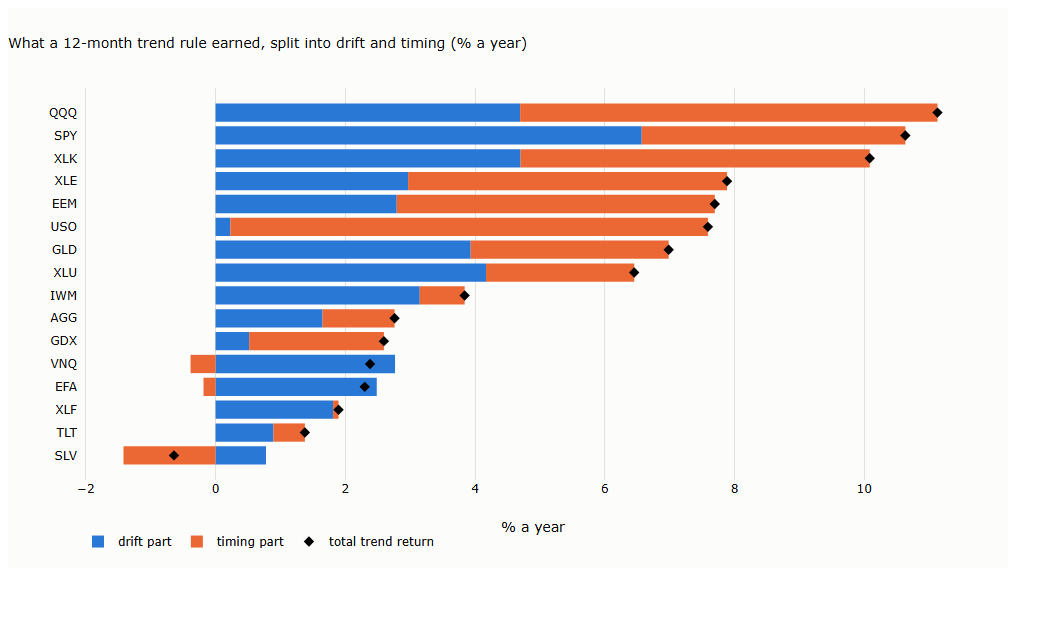

In [8]:
d_ = dec.drop("median").sort_values("trend return")
fig = go.Figure()
fig.add_bar(y=d_.index, x=d_["drift part"], name="drift part", orientation="h", marker_color=SERIES[0])
fig.add_bar(y=d_.index, x=d_["timing part"], name="timing part", orientation="h", marker_color=SERIES[1])
fig.add_scatter(y=d_.index, x=d_["trend return"], name="total trend return", mode="markers", marker=dict(color="black", size=8, symbol="diamond"))
fig.update_layout(barmode="relative", title="What a 12-month trend rule earned, split into drift and timing (% a year)",
                  xaxis_title="% a year", height=560, width=1000, margin=dict(t=80, l=70), legend=dict(orientation="h", y=-0.12, x=0))
save_figure(fig, "05_01_drift_timing", FIG)
fig

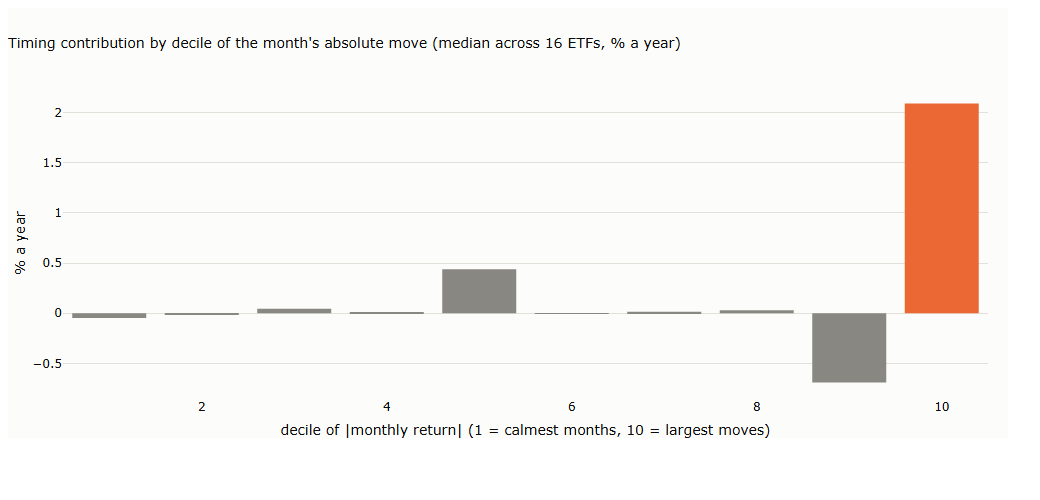

In [9]:
fig = go.Figure()
fig.add_bar(x=[str(i + 1) for i in by_decile.index], y=by_decile.values, marker_color=[MUTED] * 9 + [SERIES[1]])
fig.update_layout(title="Timing contribution by decile of the month's absolute move (median across 16 ETFs, % a year)",
                  xaxis_title="decile of |monthly return| (1 = calmest months, 10 = largest moves)", yaxis_title="% a year",
                  height=430, width=1000, margin=dict(t=80))
save_figure(fig, "05_02_timing_episodes", FIG)
fig

## 3. Understanding the market first: five questions

### 3.1 Is there a drift, and how precisely is it known? (Table 3.1)

Average annual log return, with its standard error (annual volatility divided by the square root of the number
of years) and the ratio of the two.

In [10]:
rows = {}
for t in TICKERS:
    r = R[t].dropna()
    yrs = len(r) / 12
    mu, vol = 12 * r.mean(), np.sqrt(12) * r.std()
    rows[t] = {"years": yrs, "drift % a year": 100 * mu, "volatility % a year": 100 * vol,
               "standard error of drift": 100 * vol / np.sqrt(yrs), "t-statistic": mu / (vol / np.sqrt(yrs))}
drift_tab = pd.DataFrame(rows).T
drift_tab.loc["median"] = drift_tab.median()
display(drift_tab.round(2))

,years,drift % a year,volatility % a year,standard error of drift,t-statistic
SPY,33.67,10.27,14.80,2.55,4.02
QQQ,27.50,10.25,23.52,4.49,2.28
IWM,26.33,8.00,20.16,3.93,2.04
EFA,25.08,6.33,16.81,3.36,1.89
EEM,23.42,9.33,20.88,4.31,2.16
XLE,27.75,8.58,25.08,4.76,1.80
XLF,27.75,5.65,21.27,4.04,1.40
XLK,27.75,10.03,23.28,4.42,2.27
XLU,27.75,6.89,15.34,2.91,2.37
VNQ,22.00,6.94,22.02,4.69,1.48


### 3.3 How fast can it fall, and how much happens while the market is closed? (Table 3.2)

Daily data. Worst one-day close-to-close return; worst overnight gap (open against the previous close); the worst
day in units of the trailing 252-day daily volatility; and the share of a day's variance that arrives overnight.

In [11]:
D = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")
O_, C_ = D["open"][TICKERS], D["close"][TICKERS]
rows = {}
for t in TICKERS:
    c, o = C_[t].dropna(), O_[t].dropna()
    r = np.log(c).diff().dropna()
    gap = np.log(o / c.shift(1)).reindex(r.index).dropna()
    intraday = np.log(c / o).reindex(r.index).dropna()
    sd = r.rolling(252).std().shift(1)
    z = (r / sd).dropna()
    rows[t] = {"worst day %": 100 * r.min(), "worst day": f"{r.idxmin():%Y-%m-%d}", "worst overnight gap %": 100 * gap.min(),
               "worst day in sd": z.min(), "days beyond 5 sd (per 1,000)": 1000 * (z.abs() > 5).mean(),
               "overnight share of variance": gap.var() / (gap.var() + intraday.var())}
speed = pd.DataFrame(rows).T
display(speed.round(2))
num = speed.drop(columns="worst day").astype(float)
print("median:", num.median().round(2).to_dict())

,worst day %,worst day,worst overnight gap %,worst day in sd,"days beyond 5 sd (per 1,000)",overnight share of variance
SPY,-11.588659,2020-03-16,-11.035683,-9.237063,2.793296,0.329019
QQQ,-12.759217,2020-03-16,-9.934752,-8.228932,1.793186,0.27911
IWM,-14.233457,2020-03-16,-9.520938,-9.240509,1.409774,0.302775
EFA,-11.836878,2008-09-29,-12.720646,-11.183864,2.636349,0.581351
EEM,-17.63337,2008-10-15,-13.133557,-9.177409,2.472188,0.529209
XLE,-22.490989,2020-03-09,-19.215806,-15.795052,2.224199,0.337029
XLF,-18.232166,2008-12-01,-17.497315,-9.431257,2.520759,0.354252
XLK,-14.866226,2020-03-16,-16.030636,-8.394853,2.075919,0.361127
XLU,-12.056126,2020-03-16,-9.468609,-10.066032,2.669039,0.245054
VNQ,-21.708387,2008-12-01,-11.100491,-13.453082,2.644004,0.208745


median: {'worst day %': -14.55, 'worst overnight gap %': -11.85, 'worst day in sd': -9.77, 'days beyond 5 sd (per 1,000)': 2.15, 'overnight share of variance': 0.36}


### 3.4 Does it decay? Trend returns by period (Table 3.3)

The 12-month rule's return, drift part and timing part by decade, median across the ETFs available in each period.

In [12]:
periods = {"2000-2009": ("2000", "2009"), "2010-2019": ("2010", "2019"), "2020-2026": ("2020", "2026")}
rows = {}
for name, (a, b) in periods.items():
    vals = []
    for t in TICKERS:
        d = trend_frame(t).loc[a:b]
        if len(d) < 60:
            continue
        s, x = d.s, d.r
        tot = (s * x).mean(); dr = s.mean() * x.mean()
        vals.append({"trend": 1200 * tot, "drift part": 1200 * dr, "timing part": 1200 * (tot - dr),
                     "long side": 1200 * x[s > 0].sum() / len(x), "short side": 1200 * (-x[s < 0]).sum() / len(x)})
    v = pd.DataFrame(vals)
    rows[name] = {"ETFs": len(v), **v.median().to_dict()}
decay = pd.DataFrame(rows).T
display(decay.round(2))

,ETFs,trend,drift part,timing part,long side,short side
2000-2009,11.0,9.10,1.28,9.24,5.24,3.32
2010-2019,16.0,2.06,2.30,-2.54,3.24,-1.93
2020-2026,16.0,5.96,4.13,-0.33,9.68,-3.10


### 3.5 Intervention: zero rates against the rest (Table 3.4)

Months in which the 3-month US Treasury bill yielded below 0.25% (policy rates at zero: December 2008 to late
2015, and March 2020 to early 2022) against all other months. Median across ETFs, % a year.

In [13]:
tb = pd.read_csv(RAW / "fred_DTB3.csv", parse_dates=["observation_date"], index_col="observation_date")["DTB3"]
tb = pd.to_numeric(tb, errors="coerce").resample("ME").mean()
zero = (tb < 0.25)
rows = {}
for label, flag in (("zero rates", True), ("other months", False)):
    vals = []
    for t in TICKERS:
        d = trend_frame(t).loc["2000":]
        m = zero.reindex(d.index).fillna(False) == flag
        d = d[m]
        s, x = d.s, d.r
        tot = (s * x).mean(); dr = s.mean() * x.mean()
        vals.append({"trend": 1200 * tot, "drift part": 1200 * dr, "timing part": 1200 * (tot - dr),
                     "long side": 1200 * x[s > 0].sum() / len(x), "short side": 1200 * (-x[s < 0]).sum() / len(x)})
    v = pd.DataFrame(vals)
    rows[label] = {"months (SPY)": int((zero.reindex(trend_frame("SPY").loc["2000":].index).fillna(False) == flag).sum()), **v.median().to_dict()}
policy = pd.DataFrame(rows).T
display(policy.round(2))

,months (SPY),trend,drift part,timing part,long side,short side
zero rates,108.0,3.34,2.90,-2.74,7.39,-4.08
other months,213.0,7.20,1.16,6.15,5.01,2.09
